# AMC 2026 – Round 1: Strategic Asset Allocation (Group 3)
This notebook builds our Strategic Asset Allocation (SAA), checks it against the risk budget, backtests it, computes the figures of the three report checkpoints and turns the weights into the number of shares to enter in Bloomberg.

### Round 1 rules
- Initial capital: **USD 100 million**
- **Long-only ETFs** tracking broad asset classes · no single stocks · no short positions · no leverage · no leveraged ETFs
- Asset classes, sectors, and geographical areas are freely chosen · **no common benchmark**
- Cash in **USD** is allowed and **earns 0**
- Choose and justify the allocation method: mean-variance, minimum variance, equal weight, risk parity, or another rule
- Target ex-ante volatility: **8% per year**, required to be between **7% and 9%**
- Estimate ex-ante volatility from the **annualized covariance matrix of monthly USD returns**, using the **last 60 months where available**
- Report the **1-month 5% VaR**, both as a **percentage** and in **USD**
- Backtest the SAA with **monthly rebalancing**
- Historical analysis should include **Sharpe Ratio, volatility, maximum drawdown, 5% VaR, and cumulative returns**
- During the actual challenge, performance is ranked by the **realized Sharpe Ratio**, using the **1-month US Treasury bill rate** as the risk-free rate
- The SAA remains unchanged until **Round 2**

### Setup
Libraries, data sources, the parameters of the Round 1 rules and `show`, the helper that formats the numbers of every table (percentages, ratios with 2 decimals, USD amounts with thousands separators).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from pathlib import Path

DATA_FILE = Path("../Data Round 1/AMC_adjusted_prices_final.csv")       # Bloomberg export, adjusted prices
RF_URL    = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS1MO"  # FRED 1-month T-bill, daily, % per year

CAPITAL    = 100_000_000   # USD 100 million
WINDOW     = 60            # months used to estimate the covariance matrix
VOL_MIN    = 0.07          # volatility band of the guidelines
VOL_TARGET = 0.08
VOL_MAX    = 0.09

# Number formats of the tables: 7.39%, 0.55, 3,860,465
PCT, DEC, USD = "{:.2%}", "{:.2f}", "{:,.0f}"

def show(df, fmt=PCT, special=None, axis=0):
    """Table with readable numbers: every number in `fmt`, except the rows (axis=0)
    or columns (axis=1) listed in `special` as {label: format}."""
    num = df.select_dtypes("number").columns
    df = df.copy()
    df[num] = df[num].mask(df[num].abs() < 5e-5, 0)   # optimizer noise (e.g. -1e-12) shown as 0.00%, not -0.00%
    styler = df.style.format(fmt, subset=num, na_rep="")
    if isinstance(df.index, pd.DatetimeIndex):
        styler = styler.format_index("{:%d %b %Y}")      # dates without the time
    for label, f in (special or {}).items():
        subset = pd.IndexSlice[[label], num] if axis == 0 else pd.IndexSlice[:, [label]]
        styler = styler.format(f, subset=subset, na_rep="")
    return styler

## 1. Load the data
- **Bloomberg export** (`AMC_adjusted_prices_final.csv`): daily **adjusted** prices (dividends and splits included), row 1 = asset class, row 2 = Bloomberg ticker, dates dd/mm/yyyy, `#N/A N/A` before an ETF exists
- Bloomberg adjusts prices backwards, so the **last** adjusted price equals the raw close: it gives the number of shares in section 9. BCOMTR is an index, so section 9 uses the close of BCI US Equity, the ETF that tracks it
- **Risk-free rate**: FRED series `DGS1MO`, the daily 1-month T-bill rate in % per year (from July 2001), downloaded at each run. Monthly average / 100 / 12 = monthly rate in decimals

In [2]:
# Two header rows (asset class, ticker); Bloomberg error codes become NaN
raw = pd.read_csv(DATA_FILE, header=[0, 1], index_col=0, na_values=["#NOME?", "#N/A N/A"])
raw.index = pd.to_datetime(raw.index, format="%d/%m/%Y")
raw = raw[raw.index.notna()]               # drop the rows without a date at the end of the export

### Baskets
One basket per asset class of row 1 of the file, used by the basket method (section 7). BIL is the cash leg, so it is not in a basket.

In [3]:
# Row 1 names the asset class only above the first ticker of each block: the empty cells ("Unnamed: ...") are filled forward
asset_class = raw.columns.get_level_values(0).to_series().mask(lambda s: s.str.startswith("Unnamed")).ffill()
asset_class = asset_class.str.strip().str.title()                         # "equity" -> "Equity"
asset_class.index = raw.columns.get_level_values(1).str.split().str[0]   # short tickers
asset_class = asset_class.drop("BIL")
BASKETS = {c: list(asset_class.index[asset_class == c]) for c in asset_class.unique()}
BASKETS

{'Equity': ['VTI', 'VEA', 'IEMG'],
 'Bonds': ['BND', 'BNDX', 'TIP'],
 'Commodities': ['GLD', 'BCOMTR']}

### Prices and risk-free rate
Daily prices with the short tickers as column names (last five days shown), and the monthly 1-month T-bill rate.

In [4]:
prices = raw.droplevel(0, axis=1)                          # keep the tickers only
BBG = {c.split()[0]: c for c in prices.columns}            # short ticker -> Bloomberg ticker, e.g. "VTI" -> "VTI US EQUITY"
prices = prices.rename(columns=lambda c: c.split()[0])
BBG_TRADE = {**BBG, "BCOMTR": "BCI US EQUITY"}             # tickers we hold: BCI, the ETF that tracks the BCOMTR index
NAMES = {"VTI":    "Vanguard Total Stock Market ETF",
         "VEA":    "Vanguard FTSE Developed Markets ETF",
         "IEMG":   "iShares Core MSCI Emerging Markets ETF",
         "BND":    "Vanguard Total Bond Market ETF",
         "BNDX":   "Vanguard Total International Bond ETF",
         "TIP":    "iShares TIPS Bond ETF",
         "GLD":    "SPDR Gold Shares",
         "BCOMTR": "abrdn Bloomberg All Commodity Strategy K-1 Free ETF",
         "BIL":    "SPDR Bloomberg 1-3 Month T-Bill ETF"}

ASSETS = list(prices.columns.drop("BIL"))   # risky ETFs, the inputs of the optimizer
n = len(ASSETS)                             # BIL, the cash leg, gets 1 - sum of the risky weights
close = prices.ffill()                      # last adjusted price = raw close, used in section 9

# 1-month T-bill: average daily rate of each month (days without a rate skipped), from % per year to a decimal per month
tbill = pd.read_csv(RF_URL, index_col=0, parse_dates=True).iloc[:, 0]
rf_m  = pd.to_numeric(tbill, errors="coerce").resample("ME").mean() / 100 / 12
show(prices.tail(), "{:,.2f}")

,VTI,VEA,IEMG,BND,BNDX,TIP,GLD,BCOMTR,BIL
09 Oct 2026,381.57,69.95,80.63,70.25,46.97,104.50,382.15,374.67,91.50
12 Oct 2026,381.32,70.06,80.22,70.33,47.01,104.56,381.67,375.57,91.52
13 Oct 2026,376.88,69.30,78.64,70.40,47.05,104.82,375.99,373.53,91.52
14 Oct 2026,378.42,69.66,78.09,70.81,47.21,105.29,382.71,373.11,91.54
15 Oct 2026,378.42,69.66,78.09,70.81,47.21,105.29,382.71,373.24,91.54


## 2. Monthly returns
Month-end prices, then simple monthly returns $R_t = P_t / P_{t-1} - 1$ (last five months shown). BIL is taken out of `R` and kept as `R_bil`, the return of the cash leg.

In [5]:
prices = prices.ffill().dropna()          # holidays: last available price; start when every ETF exists

monthly = prices.resample("ME").last()    # last price of each month
if prices.index[-1] < prices.index[-1] + pd.offsets.BMonthEnd(0):
    monthly = monthly.iloc[:-1]           # drop the current month if it is not complete

R = monthly.pct_change().dropna()         # monthly simple returns
R_bil = R.pop("BIL")                      # cash leg, removed from R: R = risky ETFs only

rf = rf_m.reindex(R.index).ffill()        # risk-free rate on the dates of R
show(R.tail())

,VTI,VEA,IEMG,BND,BNDX,TIP,GLD,BCOMTR
31 May 2026,5.10%,4.58%,8.30%,0.09%,0.53%,-0.08%,-2.82%,-2.22%
30 Jun 2026,-0.82%,-1.59%,-4.58%,0.17%,0.56%,-0.69%,-9.89%,-9.58%
31 Jul 2026,1.24%,0.97%,-3.13%,-0.90%,-0.64%,-0.49%,0.30%,6.35%
31 Aug 2026,0.36%,1.51%,4.25%,-0.15%,-0.94%,-0.05%,6.74%,10.01%
30 Sep 2026,0.25%,-2.39%,-0.26%,-2.02%,-0.77%,-2.34%,-3.53%,-0.37%


## 3. Descriptive analysis
Annualized and cumulative return, annualized volatility, Sharpe and Sortino Ratios (excess return over the T-bill; Sortino divides by the downside deviation only) and maximum drawdown of each ETF over the full sample, and the growth of USD 1. `perf` and `perf_table` are reused for every backtest of section 8.

,Ann. return,Cum. return,Ann. vol,Sharpe,Sortino,Max drawdown
VTI,14.34%,461.49%,15.70%,0.79,1.22,-25.09%
VEA,9.22%,187.62%,15.58%,0.47,0.70,-27.69%
IEMG,8.32%,146.52%,17.20%,0.38,0.55,-34.00%
BND,1.90%,26.69%,4.87%,0.01,0.01,-17.16%
BNDX,2.36%,35.09%,4.19%,0.12,0.16,-14.75%
TIP,2.16%,31.06%,4.85%,0.06,0.08,-12.94%
GLD,9.93%,215.99%,15.70%,0.51,0.86,-24.63%
BCOMTR,3.93%,45.94%,14.60%,0.14,0.20,-53.14%


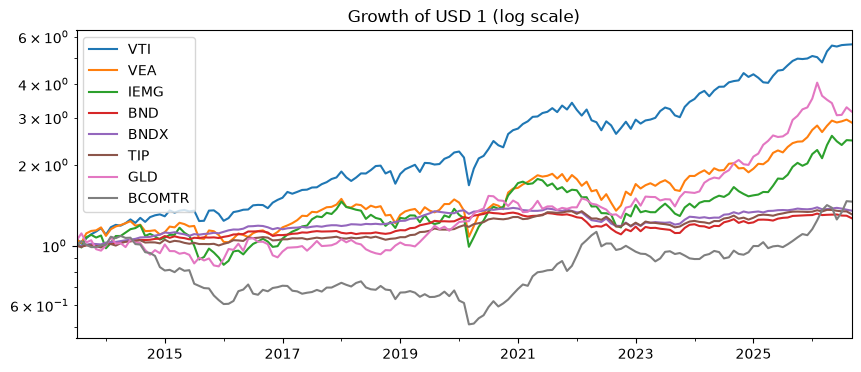

In [6]:
def perf(r, rf):
    wealth = (1 + r).cumprod()                                  # value of USD 1 invested
    excess = r - rf
    downside = np.sqrt((excess.clip(upper=0) ** 2).mean())      # downside deviation of the excess return
    return pd.Series({
        "Ann. return":  r.mean() * 12,
        "Cum. return":  wealth.iloc[-1] - 1,
        "Ann. vol":     r.std() * np.sqrt(12),
        "Sharpe":       excess.mean() / r.std() * np.sqrt(12),
        "Sortino":      excess.mean() / downside * np.sqrt(12),
        "Max drawdown": (wealth / wealth.cummax() - 1).min(),   # cummax = running peak
    })

def perf_table(returns, rf):
    """perf of each column of `returns`, one row per column."""
    table = pd.DataFrame({c: perf(returns[c], rf) for c in returns.columns}).T
    return show(table, special={"Sharpe": DEC, "Sortino": DEC}, axis=1)

display(perf_table(R, rf))

(1 + R).cumprod().plot(figsize=(10, 4), logy=True, title="Growth of USD 1 (log scale)")
plt.show()

## 4. Inputs: the last 60 months
The inputs of the allocation, estimated on the last 60 complete months as the guidelines require: annualized covariance matrix `V`, volatilities, correlations, and expected excess returns `mu` (average monthly return minus the T-bill, × 12). Our SAA uses only `V`; `mu` is used by Max Sharpe and MVO. Sources: Bloomberg adjusted prices (BCOMTR index as the proxy for BCI) and the FRED 1-month T-bill.

In [7]:
est = R.iloc[-WINDOW:]                                      # last 60 months
V = est.cov() * 12                                          # annualized covariance matrix
vol = pd.Series(np.sqrt(np.diag(V)), index=ASSETS)          # annualized volatilities
corr = V / np.outer(vol, vol)                               # correlation matrix
mu = est.sub(rf.iloc[-WINDOW:], axis=0).mean() * 12         # annualized expected excess returns

print(f"Estimation window: {est.index[0]:%b %Y} - {est.index[-1]:%b %Y} ({est.count().min()} monthly returns for every ETF)")
display(show(pd.DataFrame({"Vol": vol, "Expected excess return": mu})))
show(corr, DEC).background_gradient(cmap="RdBu_r", vmin=-1, vmax=1)

Estimation window: Oct 2021 - Sep 2026 (60 monthly returns for every ETF)


,Vol,Expected excess return
VTI,15.24%,8.97%
VEA,15.67%,7.02%
IEMG,16.28%,5.86%
BND,6.76%,-4.25%
BNDX,5.57%,-3.74%
TIP,6.00%,-3.87%
GLD,17.08%,14.58%
BCOMTR,15.36%,8.10%


,VTI,VEA,IEMG,BND,BNDX,TIP,GLD,BCOMTR
VTI,1.00,0.82,0.72,0.50,0.53,0.53,0.14,0.09
VEA,0.82,1.00,0.81,0.64,0.58,0.62,0.42,0.20
IEMG,0.72,0.81,1.00,0.56,0.47,0.53,0.44,0.24
BND,0.50,0.64,0.56,1.00,0.89,0.90,0.46,-0.06
BNDX,0.53,0.58,0.47,0.89,1.00,0.85,0.41,-0.13
TIP,0.53,0.62,0.53,0.90,0.85,1.00,0.47,0.12
GLD,0.14,0.42,0.44,0.46,0.41,0.47,1.00,0.31
BCOMTR,0.09,0.20,0.24,-0.06,-0.13,0.12,0.31,1.00


## 5. Risk tools
Ex-ante volatility $\sqrt{w^\top V w}$, risk contributions (share of the portfolio variance due to each ETF, summing to 1) and the 1-month 5% VaR under normality, $1.645 \, \sigma / \sqrt{12}$, as a fraction of capital.

In [8]:
def port_vol(w, V):
    w = np.asarray(w)
    return np.sqrt(w @ V @ w)                 # ex-ante annual volatility

def risk_contrib(w, V):
    w = np.asarray(w)
    return w * (V @ w) / (w @ V @ w)          # share of the variance due to each ETF (sums to 1)

def var_normal(vol_annual):
    return 1.645 * vol_annual / np.sqrt(12)   # 1-month 5% VaR, fraction of capital

## 6. Simple rules
Equal weight and risk parity (weights ∝ 1/σ) on the risky ETFs, fully invested. They are the robust benchmarks of CP2.

In [9]:
def w_equal(V):
    return np.ones(len(V)) / len(V)        # 1/N each

def w_riskparity(V):
    inv_vol = 1 / np.sqrt(np.diag(V))      # 1 / sigma_i
    return inv_vol / inv_vol.sum()         # weights sum to 1

## 7. Constrained optimizations under the AMC rules
The simple rules ignore the 7–9% volatility band, so the other allocations are solved numerically with `scipy` (`SLSQP`, starting from equal weights).

**Constraints common to all the problems** (`amc_constraints`):

$$
0 \le w_i \le 1 \;\;\text{(long-only)}, \qquad
\sum_{i=1}^{N} w_i \le 1 \;\;\text{(no leverage, } w_{BIL} = 1 - \textstyle\sum_i w_i \text{)}, \qquad
7\% \le \sqrt{w^\top V w} \le 9\%
$$

| Portfolio | Objective | Extra constraint |
|---|---|---|
| Minimum variance | $\min_w \; \sqrt{w^\top V w}$ | – |
| Maximum Sharpe | $\max_w \; \dfrac{w^\top \mu^e}{\sqrt{w^\top V w}}$ | – |
| Risk parity (ERC) | $\min_w \; \sum_i \left( \dfrac{w_i (Vw)_i}{w^\top V w} - \dfrac{1}{N} \right)^2$ | – |
| Mean-variance @ 8% | $\max_w \; w^\top \mu^e$ | $\sqrt{w^\top V w} = 8\%$ |
| Maximum diversification (MDP) | $\max_w \; \dfrac{w^\top \sigma}{\sqrt{w^\top V w}}$ | – |
| Basket method | $\min_{w_B} \; \sum_k \left( \dfrac{w_{B,k} (V_B w_B)_k}{w_B^\top V_B w_B} - b_k \right)^2$ | ERC within each basket |

**Basket method.** One basket per asset class (Equity, Bonds, Commodities). Within each basket the weights are ERC: each ETF carries the same share of the basket's variance. Across the baskets, risk budgeting on the covariance matrix $V_B$ of the basket returns: budget $b_E$ to equity and $(1-b_E)/2$ to each of the other two baskets, under the same AMC constraints. Four equity budgets are compared.

`scipy` only minimizes, so Max Sharpe, MVO and MDP minimize the negative of their objective.

In [10]:
def amc_constraints(V):
    """No leverage (rest in BIL) and vol between 7% and 9%; long-only is set by the bounds in solve."""
    return [
        {"type": "ineq", "fun": lambda w: 1 - w.sum()},                 # sum of the weights <= 1, rest in BIL
        {"type": "ineq", "fun": lambda w: port_vol(w, V) - VOL_MIN},    # vol >= 7%
        {"type": "ineq", "fun": lambda w: VOL_MAX - port_vol(w, V)},    # vol <= 9%
    ]

amc = amc_constraints(V.values)

def solve(objective, constraints=amc, size=n):
    res = minimize(objective,
                   x0=np.ones(size) / size,
                   method="SLSQP",
                   bounds=[(0, 1)] * size,   # long-only
                   constraints=constraints)
    return res.x

# 1. Minimum variance
w_minvar = solve(lambda w: port_vol(w, V.values))

# 2. Maximum Sharpe
w_maxsr = solve(lambda w: -(w @ mu.values) / port_vol(w, V.values))

# 3. Equal risk contribution
w_erc = solve(lambda w: ((risk_contrib(w, V.values) - 1 / n) ** 2).sum())

# 4. Mean-variance at exactly 8%
mvo_constraints = amc + [{"type": "eq", "fun": lambda w: port_vol(w, V.values) - VOL_TARGET}]
w_mvo = solve(lambda w: -(w @ mu.values), mvo_constraints)

# 5. Maximum diversification
w_mdp = solve(lambda w: -(w @ vol.values) / port_vol(w, V.values))

# 6. Basket method, one allocation per equity risk budget b_E
EQUITY_BUDGETS = {"Basket 1/3": 1/3, "Basket 50/25/25": 0.50, "Basket 60/20/20": 0.60, "Basket 70/15/15": 0.70}

def w_erc_within(V):
    """ERC weights inside one basket, fully invested."""
    return solve(lambda w: ((risk_contrib(w, V) - 1 / len(V)) ** 2).sum(),
                 [{"type": "eq", "fun": lambda w: w.sum() - 1}], size=len(V))

def w_basket(V, R_est, b_E):
    V = np.asarray(V)
    idx = {b: [ASSETS.index(t) for t in tickers] for b, tickers in BASKETS.items()}   # positions of each basket in ASSETS
    within = {b: w_erc_within(V[np.ix_(i, i)]) for b, i in idx.items()}                 # ERC within each basket
    R_b = pd.DataFrame({b: R_est.iloc[:, i] @ within[b] for b, i in idx.items()})     # monthly return of each basket
    V_b = R_b.cov().values * 12                                                         # covariance matrix of the baskets
    budget = np.array([b_E if b == "Equity" else (1 - b_E) / (len(BASKETS) - 1) for b in BASKETS])
    w_b = solve(lambda x: ((risk_contrib(x, V_b) - budget) ** 2).sum(),
                amc_constraints(V_b), size=len(BASKETS))                                # weight of each basket
    w = np.zeros(n)
    for k, (b, i) in enumerate(idx.items()):
        w[i] = w_b[k] * within[b]                                                       # basket weight x weight within
    return w

w_baskets = {name: w_basket(V, est, b_E) for name, b_E in EQUITY_BUDGETS.items()}

### 7a. Comparison of the allocations
Weights, cash in BIL, ex-ante volatility and Sharpe Ratio, and 1-month 5% VaR of every allocation, on the last 60 months.

In [11]:
W = pd.DataFrame({"EW": w_equal(V), "RP 1/vol": w_riskparity(V), "Min var": w_minvar,
                  "Max Sharpe": w_maxsr, "RP (ERC)": w_erc, "MVO @ 8%": w_mvo, "MDP": w_mdp, **w_baskets}, index=ASSETS)
summary = pd.DataFrame({c: {"BIL": 1 - W[c].sum(),
                            "Ex-ante vol": port_vol(W[c], V.values),
                            "Ex-ante Sharpe": (W[c] @ mu) / port_vol(W[c], V.values),
                            "VaR 5% 1m": var_normal(port_vol(W[c], V.values)),
                            "VaR USD": var_normal(port_vol(W[c], V.values)) * CAPITAL} for c in W})

outside = [c for c in W if not VOL_MIN <= round(summary.loc["Ex-ante vol", c], 4) <= VOL_MAX]
print("Allocations outside the 7-9% band:", ", ".join(outside) if outside else "none")
show(pd.concat([W, summary]), special={"Ex-ante Sharpe": DEC, "VaR USD": USD})

Allocations outside the 7-9% band: none


,EW,RP 1/vol,Min var,Max Sharpe,RP (ERC),MVO @ 8%,MDP,Basket 1/3,Basket 50/25/25,Basket 60/20/20,Basket 70/15/15
VTI,12.50%,8.11%,9.76%,26.03%,8.20%,24.03%,16.36%,7.15%,10.90%,13.52%,15.80%
VEA,12.50%,7.89%,9.16%,0.00%,6.69%,0.00%,0.00%,6.71%,10.24%,12.70%,14.84%
IEMG,12.50%,7.59%,9.15%,0.00%,6.79%,0.00%,0.00%,6.71%,10.23%,12.69%,14.84%
BND,12.50%,18.29%,11.33%,0.00%,16.73%,0.00%,5.27%,15.72%,13.33%,11.69%,9.39%
BNDX,12.50%,22.20%,11.62%,0.00%,21.84%,0.00%,41.40%,19.43%,16.48%,14.46%,11.61%
TIP,12.50%,20.62%,11.42%,0.00%,17.89%,0.00%,0.00%,17.99%,15.26%,13.39%,10.75%
GLD,12.50%,7.24%,9.83%,35.32%,7.97%,32.93%,10.56%,12.41%,11.15%,10.20%,8.55%
BCOMTR,12.50%,8.05%,11.01%,14.64%,13.70%,13.52%,26.42%,13.81%,12.40%,11.35%,9.51%
BIL,0.00%,0.00%,16.71%,24.02%,0.19%,29.53%,0.00%,0.06%,0.01%,0.00%,4.71%
Ex-ante vol,8.78%,7.23%,7.00%,8.61%,7.13%,8.00%,7.00%,7.39%,8.13%,8.71%,9.00%


### 7b. Our SAA
The basket method with risk budgets of 50% equity, 25% bonds and 25% commodities. Of the four equity budgets it is the closest to the 8% volatility target, and its out-of-sample Sharpe Ratio (8b, 8d) is in line with the others. It is the portfolio of the checkpoints and of section 9.

In [12]:
SAA = "Basket 50/25/25"   # our SAA: a column of W

## 8. Backtest with monthly rebalancing
Each allocation of `W` is held with fixed weights, rebalanced every month, over the full sample; the rest of the capital is in BIL. No transaction costs, since the guidelines do not mention them.

,Ann. return,Cum. return,Ann. vol,Sharpe,Sortino,Max drawdown
EW,6.52%,126.52%,8.17%,0.57,0.86,-13.84%
RP 1/vol,4.88%,85.85%,6.15%,0.49,0.73,-13.24%
Min var,5.44%,99.61%,6.45%,0.55,0.84,-10.97%
Max Sharpe,8.22%,183.48%,8.19%,0.78,1.33,-13.05%
RP (ERC),4.91%,86.59%,6.25%,0.49,0.72,-11.91%
MVO @ 8%,7.75%,167.93%,7.60%,0.77,1.33,-12.17%
MDP,5.51%,101.34%,6.57%,0.56,0.82,-12.37%
Basket 1/3,5.13%,91.60%,6.46%,0.50,0.76,-11.95%
Basket 50/25/25,5.92%,111.10%,7.39%,0.55,0.83,-13.04%
Basket 60/20/20,6.48%,125.34%,8.12%,0.57,0.85,-14.36%


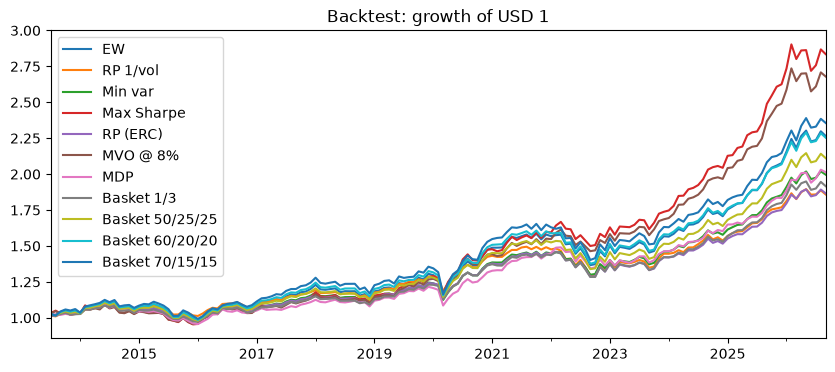

In [13]:
def backtest(w, R):
    """Monthly returns of fixed weights w, rebalanced every month: w'R_t + (1 - sum w) R_BIL,t."""
    w = np.asarray(w)
    return pd.Series(R.values @ w + (1 - w.sum()) * R_bil[R.index].values, index=R.index)

bt = pd.DataFrame({c: backtest(W[c], R) for c in W.columns})   # one column per allocation
display(perf_table(bt, rf))

(1 + bt).cumprod().plot(figsize=(10, 4), title="Backtest: growth of USD 1")
plt.show()

### 8b. Hold-out test: the months before the estimation window
The weights in `W` were estimated on the last 60 months, which are also the last 60 months of the backtest above, so part of that backtest is in-sample. Here the same weights are tested only on the months before the estimation window, which the optimizer never saw.
- No in-sample months, so Max Sharpe and MVO get no advantage from being fitted on the test data
- Look-ahead remains: weights built on the last 60 months are applied to earlier years, which no investor could have done. The test shows whether these weights hold up in another market regime, not whether the method works in real time (8c and 8d)

Estimation window: Oct 2021 - Sep 2026 (60 months, in-sample)
Hold-out sample:   Jul 2013 - Sep 2021 (99 months, out-of-sample)


,Ann. return,Cum. return,Ann. vol,Sharpe,Sortino,Max drawdown
EW,5.68%,55.60%,7.81%,0.64,0.97,-12.63%
RP 1/vol,4.89%,47.72%,5.44%,0.78,1.20,-7.91%
Min var,4.60%,43.84%,6.11%,0.64,0.97,-10.23%
Max Sharpe,5.66%,55.45%,7.85%,0.64,1.08,-13.05%
RP (ERC),4.56%,43.70%,5.69%,0.68,1.04,-9.60%
MVO @ 8%,5.28%,51.21%,7.28%,0.63,1.08,-12.17%
MDP,4.48%,42.30%,6.31%,0.60,0.89,-12.37%
Basket 1/3,4.49%,42.73%,5.86%,0.65,1.02,-10.44%
Basket 50/25/25,5.28%,51.48%,6.94%,0.66,1.01,-11.24%
Basket 60/20/20,5.84%,57.73%,7.79%,0.66,1.00,-12.77%


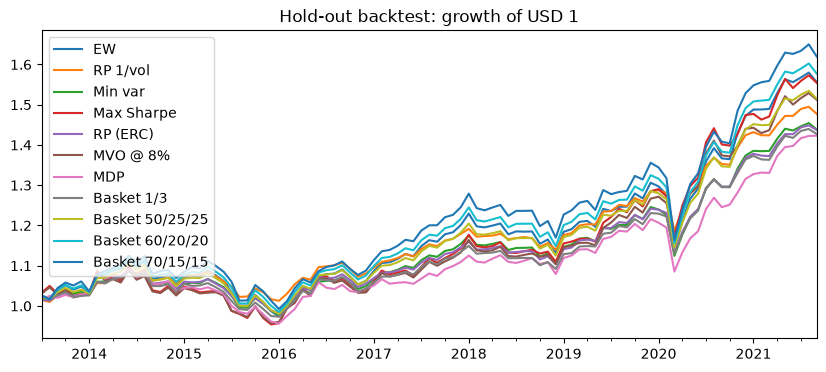

In [14]:
holdout = R.index < est.index[0]          # the months before the estimation window
R_out, rf_out = R[holdout], rf[holdout]
print(f"Estimation window: {est.index[0]:%b %Y} - {est.index[-1]:%b %Y} ({len(est)} months, in-sample)")
print(f"Hold-out sample:   {R_out.index[0]:%b %Y} - {R_out.index[-1]:%b %Y} ({len(R_out)} months, out-of-sample)")

bt_out = pd.DataFrame({c: backtest(W[c], R_out) for c in W.columns})
display(perf_table(bt_out, rf_out))

(1 + bt_out).cumprod().plot(figsize=(10, 4), title="Hold-out backtest: growth of USD 1")
plt.show()

### 8c. Split test: estimate on the first 60 months, test on the months after
Time runs forward here: `V` and `mu` are estimated on the first 60 months only, the allocations are built once with the rules of sections 6–7, and these fixed weights are held, rebalanced monthly, on all the following months.
- No look-ahead: an investor could have built these weights at the end of the estimation window
- It tests the method estimated once and then left unchanged, as our SAA until Round 2, not the weights in `W`
- It covers the same months as the walk-forward test (8d), so the two compare directly: estimate once (8c) against re-estimate every month (8d)
- Limits: a single split, so the results depend on that one window (a calm window underestimates the later volatility); the ETF list was chosen today with hindsight

Estimation window: Jul 2013 - Jun 2018 (60 months, in-sample)
Test sample:       Jul 2018 - Sep 2026 (99 months, out-of-sample)


,EW,RP 1/vol,Min var,Max Sharpe,RP (ERC),MVO @ 8%,MDP,Basket 1/3,Basket 50/25/25,Basket 60/20/20,Basket 70/15/15
VTI,12.50%,6.57%,13.36%,60.85%,16.73%,69.71%,35.84%,14.23%,16.40%,17.62%,18.80%
VEA,12.50%,6.21%,14.53%,0.00%,14.26%,0.00%,4.06%,12.72%,14.66%,15.75%,16.80%
IEMG,12.50%,4.82%,16.82%,0.00%,10.86%,0.00%,0.00%,10.46%,12.06%,12.96%,13.82%
BND,12.50%,24.67%,9.37%,0.00%,0.00%,0.00%,0.00%,7.86%,8.16%,8.57%,9.19%
BNDX,12.50%,27.71%,9.20%,39.15%,0.00%,30.29%,0.00%,9.25%,9.61%,10.09%,10.83%
TIP,12.50%,18.94%,9.78%,0.00%,25.51%,0.00%,19.08%,6.31%,6.55%,6.88%,7.39%
GLD,12.50%,4.86%,13.67%,0.00%,16.37%,0.00%,27.23%,17.18%,14.29%,12.34%,10.16%
BCOMTR,12.50%,6.22%,13.18%,0.00%,16.26%,0.00%,13.79%,21.98%,18.28%,15.79%,13.01%
BIL,0.00%,0.00%,0.08%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%
Ex-ante vol,6.08%,3.51%,7.00%,7.00%,7.00%,8.00%,7.00%,7.00%,7.00%,7.00%,7.00%


,Ann. return,Cum. return,Ann. vol,Sharpe,Sortino,Max drawdown
EW,8.37%,92.30%,9.20%,0.61,0.92,-13.84%
RP 1/vol,4.83%,46.45%,6.28%,0.33,0.47,-13.25%
Min var,9.23%,104.48%,10.24%,0.63,0.96,-14.79%
Max Sharpe,9.77%,110.83%,11.78%,0.60,0.88,-18.84%
RP (ERC),9.94%,116.89%,10.24%,0.70,1.07,-14.45%
MVO @ 8%,10.97%,129.48%,13.11%,0.63,0.93,-19.87%
MDP,11.96%,155.65%,10.35%,0.89,1.41,-13.63%
Basket 1/3,9.87%,115.86%,10.08%,0.71,1.07,-14.90%
Basket 50/25/25,9.75%,113.19%,10.35%,0.68,1.01,-15.57%
Basket 60/20/20,9.60%,110.37%,10.50%,0.65,0.98,-15.85%


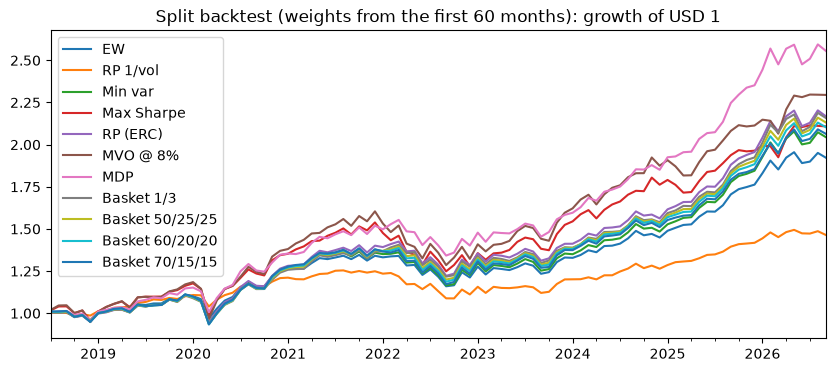

In [15]:
def allocations(V_t, mu_t, est_t):
    """The allocations of sections 6-7, rebuilt on one estimation window (returns est_t, V_t, mu_t). Also used in 8d."""
    cons = amc_constraints(V_t)
    mvo_cons = cons + [{"type": "eq", "fun": lambda w: port_vol(w, V_t) - VOL_TARGET}]
    return {"EW":         w_equal(V_t),
            "RP 1/vol":   w_riskparity(V_t),
            "Min var":    solve(lambda w: port_vol(w, V_t), cons),
            "Max Sharpe": solve(lambda w: -(w @ mu_t) / port_vol(w, V_t), cons),
            "RP (ERC)":   solve(lambda w: ((risk_contrib(w, V_t) - 1 / n) ** 2).sum(), cons),
            "MVO @ 8%":   solve(lambda w: -(w @ mu_t), mvo_cons),
            "MDP":        solve(lambda w: -(w @ np.sqrt(np.diag(V_t))) / port_vol(w, V_t), cons),
            **{name: w_basket(V_t, est_t, b_E) for name, b_E in EQUITY_BUDGETS.items()}}

est_first = R.iloc[:WINDOW]                                               # first 60 months
V_first   = (est_first.cov() * 12).values
mu_first  = (est_first.sub(rf.iloc[:WINDOW], axis=0).mean() * 12).values
W_first   = pd.DataFrame(allocations(V_first, mu_first, est_first), index=ASSETS)[W.columns]

R_test, rf_test = R.iloc[WINDOW:], rf.iloc[WINDOW:]                       # all the months after
print(f"Estimation window: {est_first.index[0]:%b %Y} - {est_first.index[-1]:%b %Y} ({len(est_first)} months, in-sample)")
print(f"Test sample:       {R_test.index[0]:%b %Y} - {R_test.index[-1]:%b %Y} ({len(R_test)} months, out-of-sample)")

# Weights from the first 60 months, with BIL and the ex-ante vol (to compare with the realized "Ann. vol" below)
first_summary = pd.DataFrame({c: {"BIL": 1 - W_first[c].sum(), "Ex-ante vol": port_vol(W_first[c], V_first)} for c in W_first})
display(show(pd.concat([W_first, first_summary])))

bt_first = pd.DataFrame({c: backtest(W_first[c], R_test) for c in W_first.columns})
display(perf_table(bt_first, rf_test))

(1 + bt_first).cumprod().plot(figsize=(10, 4), title="Split backtest (weights from the first 60 months): growth of USD 1")
plt.show()

### 8d. Walk-forward test: re-estimate every month with past data only
At the end of every month, `V` and `mu` are estimated on the previous 60 months only, the allocations are rebuilt with the rules of sections 6–7 and held during the next month, as an investor would have done in real time.
- It tests the method (e.g. "MVO at 8% on 60-month inputs"), not the weights we hold until Round 2
- Fully out-of-sample: the weights of each month only use data available before that month
- Limits: it starts only after the first 60 months (July 2018); it ignores the transaction costs of changing the weights every month; the ETF list was chosen today with hindsight; Min var has no unique solution (every portfolio at exactly 7% volatility is optimal), so its result depends on the starting point of the optimizer
- The loop runs about 2,000 optimizations, which takes several seconds

Walk-forward: Jul 2018 - Sep 2026 (99 months, out-of-sample)


,Ann. return,Cum. return,Ann. vol,Sharpe,Sortino,Max drawdown
EW,8.37%,92.30%,9.20%,0.61,0.92,-13.84%
RP 1/vol,5.43%,53.76%,6.45%,0.42,0.61,-13.39%
Min var,6.79%,69.85%,8.34%,0.48,0.69,-14.49%
Max Sharpe,9.71%,112.26%,10.55%,0.66,0.98,-15.38%
RP (ERC),6.58%,66.85%,8.47%,0.45,0.65,-13.30%
MVO @ 8%,9.32%,105.06%,10.82%,0.61,0.88,-16.13%
MDP,8.18%,90.12%,8.61%,0.63,0.97,-11.69%
Basket 1/3,6.75%,69.15%,8.52%,0.47,0.68,-13.89%
Basket 50/25/25,6.97%,71.83%,8.85%,0.48,0.68,-14.47%
Basket 60/20/20,7.11%,73.47%,9.04%,0.48,0.69,-14.71%


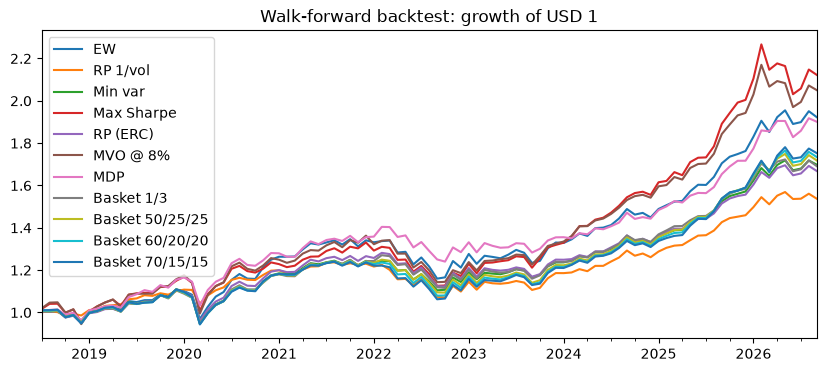

In [16]:
wf = {}
for t in range(WINDOW, len(R)):                               # t = position in R of the month we invest in
    est_t = R.iloc[t - WINDOW:t]                              # the 60 months before month t
    V_t   = (est_t.cov() * 12).values
    mu_t  = (est_t.sub(rf.iloc[t - WINDOW:t], axis=0).mean() * 12).values
    w_t   = allocations(V_t, mu_t, est_t)                     # weights chosen at the end of month t-1
    wf[R.index[t]] = {c: R.iloc[t].values @ w_t[c] + (1 - w_t[c].sum()) * R_bil.iloc[t]
                      for c in w_t}                           # return of month t, rest in BIL

bt_wf = pd.DataFrame.from_dict(wf, orient="index")[W.columns]   # one row per month, one column per allocation
rf_wf = rf.iloc[WINDOW:]
print(f"Walk-forward: {bt_wf.index[0]:%b %Y} - {bt_wf.index[-1]:%b %Y} ({len(bt_wf)} months, out-of-sample)")
display(perf_table(bt_wf, rf_wf))

(1 + bt_wf).cumprod().plot(figsize=(10, 4), title="Walk-forward backtest: growth of USD 1")
plt.show()

### 8e. Sharpe Ratios of the four backtests
One row per allocation, one column per backtest. The columns cover different periods, so compare the ranking of the allocations within each column rather than the levels across columns. Only the split (8c) and the walk-forward (8d) cover the same months: the gap between them is the effect of re-estimating every month instead of once.

In [17]:
print(f"Full sample:       {R.index[0]:%b %Y} - {R.index[-1]:%b %Y}  weights from the last 60 months, all months (the last 60 are in-sample)")
print(f"Hold-out (8b):     {R_out.index[0]:%b %Y} - {R_out.index[-1]:%b %Y}  weights from the last 60 months, the months before them")
print(f"Split (8c):        {R_test.index[0]:%b %Y} - {R_test.index[-1]:%b %Y}  weights from the first 60 months, the months after them")
print(f"Walk-forward (8d): {bt_wf.index[0]:%b %Y} - {bt_wf.index[-1]:%b %Y}  weights re-estimated every month on the previous 60")

sharpe = pd.DataFrame({
    "Full sample":       {c: perf(bt[c], rf)["Sharpe"] for c in W.columns},
    "Hold-out (8b)":     {c: perf(bt_out[c], rf_out)["Sharpe"] for c in W.columns},
    "Split (8c)":        {c: perf(bt_first[c], rf_test)["Sharpe"] for c in W.columns},
    "Walk-forward (8d)": {c: perf(bt_wf[c], rf_wf)["Sharpe"] for c in W.columns},
})
show(sharpe, DEC)

Full sample:       Jul 2013 - Sep 2026  weights from the last 60 months, all months (the last 60 are in-sample)
Hold-out (8b):     Jul 2013 - Sep 2021  weights from the last 60 months, the months before them
Split (8c):        Jul 2018 - Sep 2026  weights from the first 60 months, the months after them
Walk-forward (8d): Jul 2018 - Sep 2026  weights re-estimated every month on the previous 60


,Full sample,Hold-out (8b),Split (8c),Walk-forward (8d)
EW,0.57,0.64,0.61,0.61
RP 1/vol,0.49,0.78,0.33,0.42
Min var,0.55,0.64,0.63,0.48
Max Sharpe,0.78,0.64,0.60,0.66
RP (ERC),0.49,0.68,0.70,0.45
MVO @ 8%,0.77,0.63,0.63,0.61
MDP,0.56,0.60,0.89,0.63
Basket 1/3,0.50,0.65,0.71,0.47
Basket 50/25/25,0.55,0.66,0.68,0.48
Basket 60/20/20,0.57,0.66,0.65,0.48


## Checkpoints of the Round 1 report
The figures asked by the three checkpoints, for our SAA, in the order of the report. The choices and their reasons (self-imposed constraints, maximum acceptable drawdown, discount factor, number of variations) are written in the report. BCOMTR is the return proxy for **BCI US Equity**, the ETF we hold.

### CP1. Investment policy
Universe; objective and risk budget (ex-ante volatility, 1-month 5% VaR, maximum acceptable drawdown); weight and risk contribution of each position, and whether a single position carries more than half of the risk.

In [18]:
MAX_DD = None    # maximum acceptable drawdown, to be set by the team (e.g. -0.15)

# Universe: name, ticker held and asset class of each position
display(show(pd.DataFrame({"Name": NAMES,
                      "Bloomberg ticker": BBG_TRADE,
                      "Asset class": pd.concat([asset_class, pd.Series({"BIL": "Cash"})])}).loc[ASSETS + ["BIL"]]))

# Objective and risk budget
vol_saa = port_vol(W[SAA], V.values)
print(f"Objective: Sharpe Ratio | vol target {VOL_TARGET:.0%} (range {VOL_MIN:.0%}-{VOL_MAX:.0%}) | ex-ante vol {vol_saa:.2%} | "
      f"1-month 5% VaR {var_normal(vol_saa):.2%} = USD {var_normal(vol_saa) * CAPITAL:,.0f}")
print("Maximum acceptable drawdown:", f"{MAX_DD:.0%}" if MAX_DD is not None else "to be decided by the team")

# Weight and risk contribution of each position (BIL has zero vol, so zero risk)
cp1 = pd.DataFrame({"Weight": W[SAA], "%RC": risk_contrib(W[SAA], V.values)})
cp1.loc["BIL"] = [1 - W[SAA].sum(), 0]
top = cp1.loc[ASSETS, "%RC"]
print(f"Largest risk contribution: {top.idxmax()} {top.max():.1%} ({'above' if top.max() > 0.5 else 'below'} half of the risk)")
cp1.loc["Total"] = cp1.sum()
show(cp1)

,Name,Bloomberg ticker,Asset class
VTI,Vanguard Total Stock Market ETF,VTI US EQUITY,Equity
VEA,Vanguard FTSE Developed Markets ETF,VEA US EQUITY,Equity
IEMG,iShares Core MSCI Emerging Markets ETF,IEMG US EQUITY,Equity
BND,Vanguard Total Bond Market ETF,BND US EQUITY,Bonds
BNDX,Vanguard Total International Bond ETF,BNDX US EQUITY,Bonds
TIP,iShares TIPS Bond ETF,TIP US EQUITY,Bonds
GLD,SPDR Gold Shares,GLD US EQUITY,Commodities
BCOMTR,abrdn Bloomberg All Commodity Strategy K-1 Free ETF,BCI US EQUITY,Commodities
BIL,SPDR Bloomberg 1-3 Month T-Bill ETF,BIL US EQUITY,Cash


Objective: Sharpe Ratio | vol target 8% (range 7%-9%) | ex-ante vol 8.13% | 1-month 5% VaR 3.86% = USD 3,860,465
Maximum acceptable drawdown: to be decided by the team
Largest risk contribution: VEA 17.4% (below half of the risk)


,Weight,%RC
VTI,10.90%,15.21%
VEA,10.24%,17.42%
IEMG,10.23%,17.36%
BND,13.33%,8.34%
BNDX,16.48%,7.83%
TIP,15.26%,8.84%
GLD,11.15%,15.49%
BCOMTR,12.40%,9.51%
BIL,0.01%,0.00%
Total,100.00%,100.00%


### CP2. Comparison with the robust approaches
Our SAA next to equal weight and risk parity (weights ∝ 1/σ, same 60-month window): weight and risk contribution of each position, and the ex-ante volatility of each portfolio.

In [19]:
CP2 = [SAA, "EW", "RP 1/vol"]
cp2 = pd.concat({c: pd.DataFrame({"Weight": W[c], "%RC": risk_contrib(W[c], V.values)}) for c in CP2}, axis=1)
cp2.loc["BIL"] = [x for c in CP2 for x in (1 - W[c].sum(), 0)]                          # cash leg: weight, no risk
cp2.loc["Ex-ante vol"] = [x for c in CP2 for x in (port_vol(W[c], V.values), np.nan)]   # one vol per portfolio
show(cp2)

### CP3. Backtest protocol
Design and sample of the backtest (section 8); data used for the weights and data held out (8b); volatility, maximum drawdown and 1-month 5% VaR of the backtested SAA; backtested Sharpe Ratio, its t-statistic and the discounted value; cumulative return. The same table and plot give the historical performance and risk of our SAA for the backtest part of the analysis of the allocation.
- We rely on the held-out months (8b): the full sample also contains the estimation window, so part of it is in-sample. The full-sample figures are shown for reference
- VaR: normal, 1.645 × realized monthly volatility, the same formula as the ex-ante VaR
- t-statistic of the mean excess return: Sharpe × √years
- Discounted Sharpe: backtested Sharpe ÷ `DISCOUNT` (rule of thumb from Class 4: divide by at least 2, more when more choices were tuned)

Design: 8 ETFs + BIL, fixed weights of Basket 50/25/25, rebalanced monthly, no transaction costs
Backtest:          Jul 2013 - Sep 2026 (159 months)
Used for weights:  Oct 2021 - Sep 2026 (60 months, estimation window)
Held out (8b):     Jul 2013 - Sep 2021 (99 months)
Allocations compared in this notebook: 11


,Held out,Full sample
Months,99,159
Ann. return,5.28%,5.92%
Cum. return,51.48%,111.10%
Ann. vol,6.94%,7.39%
Max drawdown,-11.24%,-13.04%
VaR 5% 1m,3.30%,3.51%
VaR USD,"3,295,225","3,508,981"
Sharpe,0.66,0.55
Sortino,1.01,0.83
t-stat,1.91,2.00


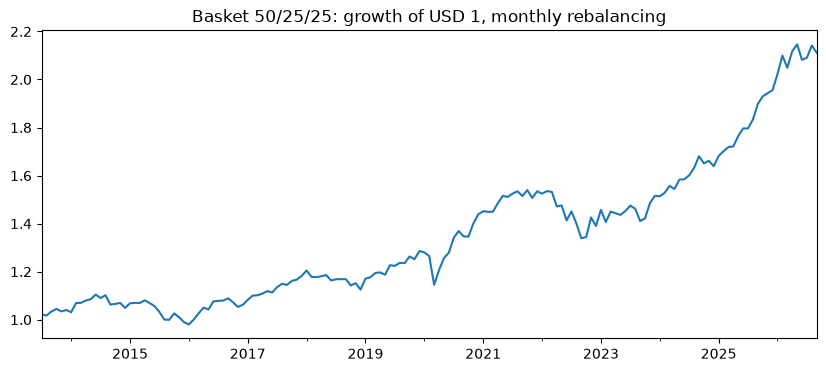

In [20]:
DISCOUNT = 2     # divide the backtested Sharpe by 2; more with more tuned choices

# Design and samples
print(f"Design: {n} ETFs + BIL, fixed weights of {SAA}, rebalanced monthly, no transaction costs")
print(f"Backtest:          {R.index[0]:%b %Y} - {R.index[-1]:%b %Y} ({len(R)} months)")
print(f"Used for weights:  {est.index[0]:%b %Y} - {est.index[-1]:%b %Y} ({len(est)} months, estimation window)")
print(f"Held out (8b):     {R_out.index[0]:%b %Y} - {R_out.index[-1]:%b %Y} ({len(R_out)} months)")
print(f"Allocations compared in this notebook: {len(W.columns)}")

# Backtested SAA on the held-out months (the figures we rely on) and on the full sample
cp3 = {}
for name, r, rf_s in [("Held out", bt_out[SAA], rf_out), ("Full sample", bt[SAA], rf)]:
    p = perf(r, rf_s)
    cp3[name] = {"Months":            len(r),
                 "Ann. return":       p["Ann. return"],
                 "Cum. return":       p["Cum. return"],
                 "Ann. vol":          p["Ann. vol"],
                 "Max drawdown":      p["Max drawdown"],
                 "VaR 5% 1m":         var_normal(p["Ann. vol"]),
                 "VaR USD":           var_normal(p["Ann. vol"]) * CAPITAL,
                 "Sharpe":            p["Sharpe"],
                 "Sortino":           p["Sortino"],
                 "t-stat":            p["Sharpe"] * np.sqrt(len(r) / 12),   # = mean excess return / (vol / sqrt(T))
                 "Discounted Sharpe": p["Sharpe"] / DISCOUNT}
display(show(pd.DataFrame(cp3), special={"Months": USD, "VaR USD": USD, "Sharpe": DEC, "Sortino": DEC,
                                         "t-stat": DEC, "Discounted Sharpe": DEC}))

# Cumulative return of our SAA over the full sample
(1 + bt[SAA]).cumprod().plot(figsize=(10, 4), title=f"{SAA}: growth of USD 1, monthly rebalancing")
plt.show()

## 9. From weights to the Bloomberg portfolio
Number of shares of each ETF: $N_i = \lfloor w_i W_0 / P_i \rfloor$, with $W_0$ = USD 100 million and $P_i$ the raw close on the last date of the data file, which must be **Friday 16 October**. Positions below 2% go to BIL; the rounding leftover stays in cash, which earns 0. The table is the portfolio description of the report (name, Bloomberg ticker, currency, shares, weight and price date of each position) and is saved to `portfolio_for_PRTU.csv`.
- Fill `BCI_CLOSE` with the raw close of BCI US Equity on that date before running this cell

In [ ]:
# 1. Final weights: positions below 2% go to BIL
w_final = W[SAA].copy()
w_final[w_final < 0.02] = 0
w_final["BIL"] = 1 - w_final.sum()

# 2. Prices and number of shares
PRICE_DATE = close.index[-1]                        # last date of the data file
px = close.loc[PRICE_DATE, w_final.index]           # raw close = last adjusted price
# BCOMTR is an index: we hold BCI US Equity, the ETF that tracks it (BCOMTR stays the return proxy in sections 2-8)
BCI_CLOSE = None                                    # raw close of BCI US Equity on PRICE_DATE, from Bloomberg
assert BCI_CLOSE is not None, "Enter the raw close of BCI US Equity in BCI_CLOSE"
px["BCOMTR"] = BCI_CLOSE

shares = np.floor(w_final * CAPITAL / px)           # whole shares, rounded down: never more than USD 100 million
value = shares * px                                 # USD invested in each ETF
w_actual = value / CAPITAL                          # actual weights after rounding

# 3. Portfolio description (report) and input for PRTU, saved next to the notebook
report = pd.DataFrame({"Name": [NAMES[t] for t in w_final.index],
                       "Bloomberg ticker": [BBG_TRADE[t] for t in w_final.index],   # tickers to enter in PRTU
                       "Currency": "USD",
                       "Shares": shares.astype(int),
                       "Close price": px.round(2),
                       "Price date": f"{PRICE_DATE:%d %b %Y}",
                       "Weight": w_actual.round(4)},
                      index=w_final.index)
report = report[report["Shares"] > 0]               # only the ETFs we actually hold
report.to_csv("portfolio_for_PRTU.csv", index=False)

# 4. Cash left and risk of the portfolio we actually buy (BIL has about zero vol)
cash = CAPITAL - value.sum()
vol_actual = port_vol(w_actual[ASSETS], V.values)
print(f"{SAA}, prices of {PRICE_DATE:%d %b %Y}")
print(f"Invested: USD {value.sum():,.0f} | cash: USD {cash:,.0f} ({cash / CAPITAL:.2%}, earns 0)")
print(f"Ex-ante vol {vol_actual:.2%} | 1-month 5% VaR {var_normal(vol_actual):.2%} = USD {var_normal(vol_actual) * CAPITAL:,.0f}")

report["USD invested"] = value[report.index]
show(report, special={"Close price": "{:,.2f}", "Shares": USD, "USD invested": USD}, axis=1)

### In Bloomberg
- `PRTU` → *Create* → **Equity**, **Shares/Par amount**, USD
- Enter each ticker of `portfolio_for_PRTU.csv` with its **number of shares** on **Saturday or Sunday** (Bloomberg uses the Friday close)
- *Action* → *Update Corporate Actions* → tick **adjust cash for dividends** and **reinvest cash dividends**
- **Share** the portfolio with the TA · monitor it with `PORT`